In [1]:
import sys
project_root = "../.."
sys.path.append(project_root)

import seaborn as sns
import torch
from IPython.display import HTML
import matplotlib.pyplot as plt

# Import project packages
from src.simulation.visualization.animation import create_animation_2d
from src.simulation.equations.navierstokes2d import NavierStokes2D

device = torch.device("cpu")
sns.set_style("ticks")
sns.set_context("paper")

In [3]:
eq = NavierStokes2D(
    Lx=1.0, Ly=1.0,
    T=5.0,                    
    n_x=64, n_y=64,
    n_t=100,
    viscosity={"type": "constant", "value": 0.0006},
    ic={"type": "grf_operator",  "normalize": True, "scale": 23.0 / 2.0},
    dt=1e-4,                   
)


snapshots = eq.solve()
frames = [snapshots[i] for i in range(len(snapshots))]
vmin = snapshots[0].min()
vmax = snapshots[0].max()
animation = create_animation_2d(frames, colormap="viridis", vmin=vmin, vmax=vmax)
HTML(animation.to_jshtml())

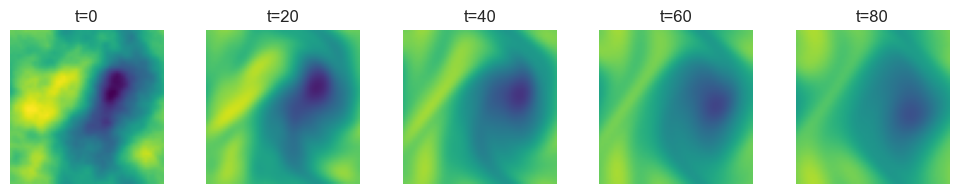

In [4]:
chosen_cmap = "viridis"  # change this to try others!

n_snapshots = len(snapshots)
step = 20
num_plots = n_snapshots // step
fig, axes = plt.subplots(1, num_plots, figsize=(2*num_plots, 2))

if num_plots == 1:
    axes = [axes]

for i, idx in enumerate(range(0, n_snapshots-1, step)):
    ax = axes[i]
    img = ax.imshow(
        snapshots[idx],
        cmap=chosen_cmap,
        vmin=snapshots.min(),
        vmax=snapshots.max()
    )
    ax.set_title(f"t={idx}")
    ax.axis("off")

plt.tight_layout()
plt.show()